# Online Shopper Purchase Intention: Exploratory Data Analysis

**Dataset:** Online Shoppers Purchasing Intention (UCI), 12,330 sessions; `Revenue` = whether the session ended in a purchase.

## Research questions
**Descriptive**
1. Which months are the most lucrative (sessions, purchases, purchase rate)?
2. How do purchases differ by visitor type?
3. How do new and returning visitors differ in purchase rate and browsing behavior?

**Relationships**

4. Are bounce rates and exit rates associated with the likelihood of purchase?
5. Which variables are most associated with a purchase?

## 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/online_shoppers_intention.csv')
df.shape

(12330, 18)

In [2]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Data overview

In [3]:
df.dtypes
# weekend? Muslim holidays?

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

In [4]:
df.isna().sum()   # no missing values

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


## 3. Variable dictionary
| Variable | Meaning |
|---|---|
| `BounceRates` | Average bounce rate of the pages visited: share of visits that left after viewing only that page. Lower = more engaged. |
| `ExitRates` | Average exit rate of the pages visited: share of pageviews that were the last in the session. |
| `PageValues` | Average Google Analytics page value of the pages visited: revenue from sessions that viewed a page before buying ÷ unique views of that page. Built from purchases, so it is closely tied to the outcome. |
| `ProductRelated` / `ProductRelated_Duration` | Number of product pages visited / total seconds spent on them |
| `SpecialDay` | Closeness of the visit date to a special day (e.g., Valentine's Day), 0–1 |
| `VisitorType` | New_Visitor, Returning_Visitor, or Other |
| `Weekend`, `Month` | Whether the session was on a weekend; month of the session |
| `Revenue` | Whether the session ended in a purchase (target) |

In [6]:
df.Month.value_counts()

# 10 months of one year (no January or April)

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

In [7]:
df['Region'].value_counts()

Region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318
Name: count, dtype: int64

In [8]:
df['VisitorType'].value_counts()
# 3 visitor types, not sure what other means.

VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

## 4. Data cleaning

**Visitor type:** `Other` has only 85 sessions and no clear definition, so it is removed.

In [9]:
clean_df = df[df["VisitorType"] != "Other"]

**Duplicates:** 121 duplicate rows are dropped (the data has no session ID, so identical rows are treated as repeats).

In [10]:
clean_df.duplicated().sum()

np.int64(121)

In [11]:
clean_df = clean_df.drop_duplicates()

**Outliers:** duration, page-count, and PageValues columns are heavily right-skewed. Rows far outside the 10th–90th percentile range are removed. BounceRates and ExitRates are kept as they are.

In [12]:
results = []

columns = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration","PageValues"
]
# "BounceRates", "ExitRates". Main variables not included in the first outliers list as the median VS mean checking shows us. We may need to check this later.
# For now, only the extreme ones are exluded

# Start with a copy of the original dataframe
final_df = clean_df.copy()

# Apply IQR method to each column
for col in columns:
    Q1 = final_df[col].quantile(0.10)
    Q3 = final_df[col].quantile(0.90)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Remove rows containing outliers
    final_df = final_df[
        (final_df[col] >= lower_bound) &
        (final_df[col] <= upper_bound)
    ]

final_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,10398.0,1.852664,2.733318,0.0,0.000000,0.000000,3.000000,17.000000
Administrative_Duration,10398.0,52.567130,91.132187,0.0,0.000000,0.000000,71.325000,559.166667
Informational,10398.0,0.253510,0.708007,0.0,0.000000,0.000000,0.000000,5.000000
Informational_Duration,10398.0,6.056548,20.377809,0.0,0.000000,0.000000,0.000000,136.000000
ProductRelated,10398.0,24.466436,25.915095,0.0,7.000000,16.000000,32.000000,158.000000
ProductRelated_Duration,10398.0,875.047827,1020.755795,0.0,158.943333,502.983333,1218.082738,5793.523810
BounceRates,10398.0,0.022699,0.048055,0.0,0.000000,0.003125,0.019048,0.200000
ExitRates,10398.0,0.045039,0.048384,0.0,0.015164,0.028000,0.051150,0.200000
PageValues,10398.0,2.604118,7.572457,0.0,0.000000,0.000000,0.000000,44.443614
SpecialDay,10398.0,0.067878,0.208276,0.0,0.000000,0.000000,0.000000,1.000000


**New variables:** browse time in minutes, and purchase as 0/1.

In [13]:
# creating a minute variable

final_df['ProductRelated_Duration_minutes'] = final_df['ProductRelated_Duration'] / 60

In [14]:
final_df["converted_revenue"] = final_df["Revenue"].astype(int)          # 1 = purchase, 0 = no purchase

## 5. Q1. Which months are the most lucrative?

In [15]:
## Which periods of revenue / timings are the most lucrative?

lucrative_period = (final_df.groupby("Month")["converted_revenue"].agg(sessions="count", purchases="sum", purchase_per_sessions = "mean")).sort_values(by='sessions', ascending= False).reset_index()
lucrative_period

,Month,sessions,purchases,purchase_per_sessions
0,May,2958,228,0.077079
1,Nov,2370,449,0.189451
2,Mar,1659,110,0.066305
3,Dec,1418,127,0.089563
4,Oct,446,70,0.156951
5,Jul,377,48,0.127321
6,Sep,374,62,0.165775
7,Aug,365,52,0.142466
8,June,253,23,0.090909
9,Feb,178,2,0.011236


In [16]:
lucrative_period['Month_n'] = pd.to_datetime(lucrative_period['Month']).dt.month
lucrative_period

/var/folders/8v/v2c4n_w51456g3mxc_p0cd200000gn/T/ipykernel_48845/4206670198.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  lucrative_period['Month_n'] = pd.to_datetime(lucrative_period['Month']).dt.month


,Month,sessions,purchases,purchase_per_sessions,Month_n
0,May,2958,228,0.077079,5
1,Nov,2370,449,0.189451,11
2,Mar,1659,110,0.066305,3
3,Dec,1418,127,0.089563,12
4,Oct,446,70,0.156951,10
5,Jul,377,48,0.127321,7
6,Sep,374,62,0.165775,9
7,Aug,365,52,0.142466,8
8,June,253,23,0.090909,6
9,Feb,178,2,0.011236,2


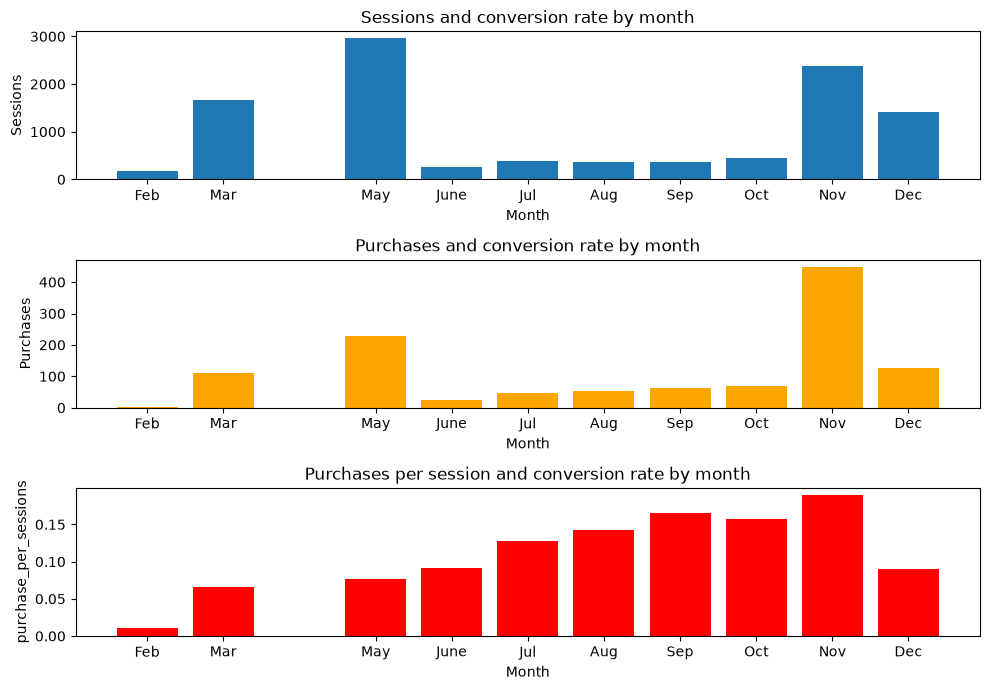

In [17]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

ax1.bar(lucrative_period['Month_n'], lucrative_period['sessions'])
ax1.set_ylabel('Sessions')
ax1.set_title('Sessions and conversion rate by month')

ax2.bar(lucrative_period['Month_n'], lucrative_period['purchases'], color='orange')
ax2.set_ylabel('Purchases')
ax2.set_title('Purchases and conversion rate by month')

ax3.bar(lucrative_period['Month_n'], lucrative_period['purchase_per_sessions'], color='red')
ax3.set_ylabel('purchase_per_sessions')
ax3.set_title('Purchases per session and conversion rate by month')

for ax in (ax1, ax2, ax3):
    ax.set_xticks(lucrative_period['Month_n'])                          # a tick at every month
    ax.set_xticklabels(lucrative_period['Month'])                        # name each tick
    ax.tick_params(labelbottom=True)     # show labels even on shared axes
    ax.set_xlabel('Month')

plt.tight_layout()
plt.show()

**Observations**
- May and November have the most sessions; November also has the most purchases, followed by May.
- November has the highest purchase rate (about 19%), more than double May's (about 8%).
- May has many visitors who did not buy as much.
- February has very few sessions (178) and only 2 purchases, too few to draw conclusions.

### Browsing behavior by month

In [18]:
lucrative_period_deep = (final_df.groupby("Month")[['converted_revenue', 'ProductRelated_Duration_minutes', 'BounceRates', 'ExitRates']].agg(sessions=('converted_revenue', 'count'),
            purchases=('converted_revenue', 'sum'),
            purchase_rate=('converted_revenue', 'mean'),
            browse_time=('ProductRelated_Duration_minutes', 'mean'),
            avg_bounce_rate=('BounceRates', 'mean'),
            avg_exit_rates=('ExitRates', 'mean')).reset_index()
)
lucrative_period_deep

,Month,sessions,purchases,purchase_rate,browse_time,avg_bounce_rate,avg_exit_rates
0,Aug,365,52,0.142466,15.722564,0.020219,0.041144
1,Dec,1418,127,0.089563,14.188723,0.020046,0.042207
2,Feb,178,2,0.011236,7.118037,0.044955,0.072826
3,Jul,377,48,0.127321,14.295361,0.026875,0.048235
4,June,253,23,0.090909,12.558263,0.036675,0.061055
5,Mar,1659,110,0.066305,11.358791,0.018778,0.043482
6,May,2958,228,0.077079,13.548917,0.027418,0.050711
7,Nov,2370,449,0.189451,19.189226,0.020944,0.041497
8,Oct,446,70,0.156951,13.667211,0.013152,0.031612
9,Sep,374,62,0.165775,14.593227,0.013487,0.032788


In [19]:
lucrative_period_deep['Month_n'] = pd.to_datetime(lucrative_period_deep['Month']).dt.month

/var/folders/8v/v2c4n_w51456g3mxc_p0cd200000gn/T/ipykernel_48845/9728749.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  lucrative_period_deep['Month_n'] = pd.to_datetime(lucrative_period_deep['Month']).dt.month


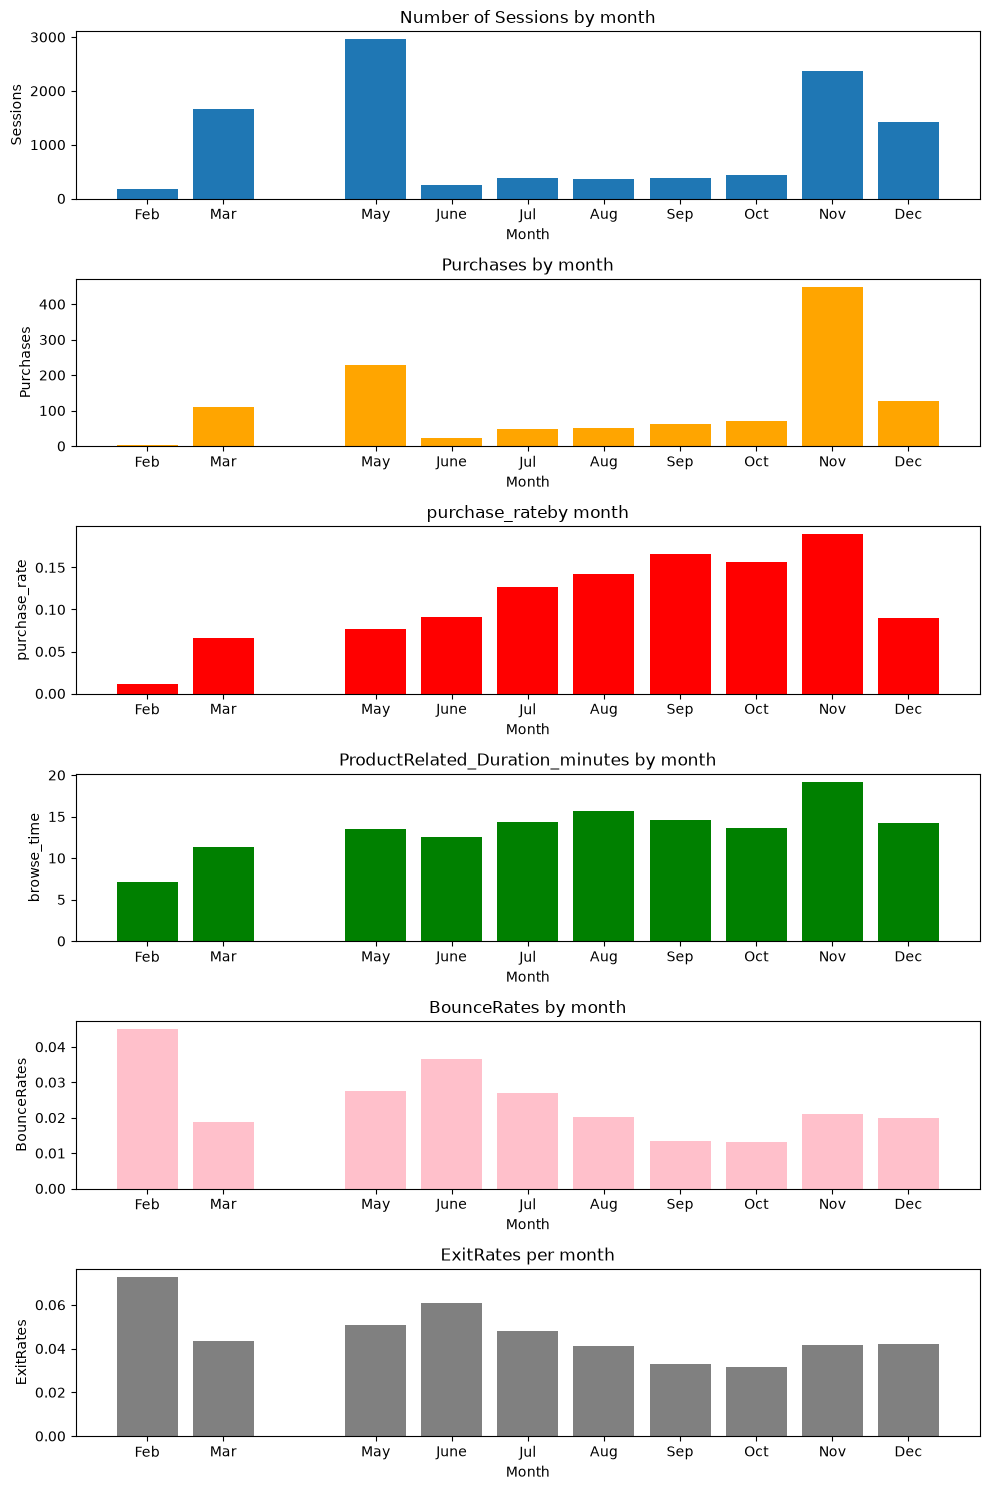

In [20]:
fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(6, 1, figsize=(10, 15), sharex=True)

ax1.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['sessions'])
ax1.set_ylabel('Sessions')
ax1.set_title('Number of Sessions by month')

ax2.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['purchases'], color='orange')
ax2.set_ylabel('Purchases')
ax2.set_title('Purchases by month')

ax3.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['purchase_rate'], color='red')
ax3.set_ylabel('purchase_rate')
ax3.set_title('purchase_rateby month')

ax4.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['browse_time'], color='green')
ax4.set_ylabel('browse_time')
ax4.set_title('ProductRelated_Duration_minutes by month')

ax5.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['avg_bounce_rate'], color='pink')
ax5.set_ylabel('BounceRates')
ax5.set_title('BounceRates by month')

ax6.bar(lucrative_period_deep['Month_n'], lucrative_period_deep['avg_exit_rates'], color='grey')
ax6.set_ylabel('ExitRates')
ax6.set_title('ExitRates per month')

for ax in (ax1, ax2, ax3, ax4, ax5, ax6):
    ax.set_xticks(lucrative_period_deep['Month_n'])                          # a tick at every month
    ax.set_xticklabels(lucrative_period_deep['Month'])                        # name each tick
    ax.tick_params(labelbottom=True)     # show labels even on shared axes
    ax.set_xlabel('Month')

plt.tight_layout()
plt.show()

## 6. Q2–Q3. Visitor type: purchases and browsing behavior

In [21]:
## Aggregate based on revenue - organize by VisitorType?
Visitor_type = final_df.groupby('VisitorType')['converted_revenue'].agg(sessions="count", purchases="sum", purchase_per_sessions = "mean").sort_values("purchase_per_sessions", ascending=False)
Visitor_type

,sessions,purchases,purchase_per_sessions
VisitorType,,,
New_Visitor,1445,248,0.171626
Returning_Visitor,8953,923,0.103094


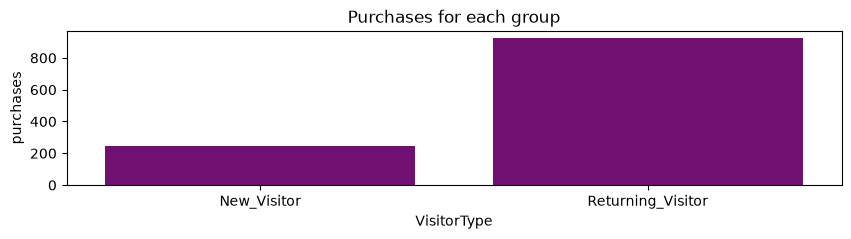

In [22]:
plt.figure(figsize = (10,2))
sns.barplot(x='VisitorType', y='purchases', data=Visitor_type, color='purple')
plt.title('Purchases for each group')
plt.show()

In [23]:
## How do new and returning visitors differ in purchase rate and browsing behavior?

new_return = (final_df.groupby('VisitorType')[['converted_revenue', 'ProductRelated_Duration_minutes', 'BounceRates', 'ExitRates']]
       .agg(sessions=('converted_revenue', 'count'),
            purchases=('converted_revenue', 'sum'),
            purchase_rate=('converted_revenue', 'mean'),
            browse_time=('ProductRelated_Duration_minutes', 'mean'),
            avg_bounce_rate=('BounceRates', 'mean'),
            avg_exit_rates=('ExitRates', 'mean')).reset_index()
)
       
new_return

,VisitorType,sessions,purchases,purchase_rate,browse_time,avg_bounce_rate,avg_exit_rates
0,New_Visitor,1445,248,0.171626,9.481692,0.005872,0.022217
1,Returning_Visitor,8953,923,0.103094,15.407656,0.025414,0.048722


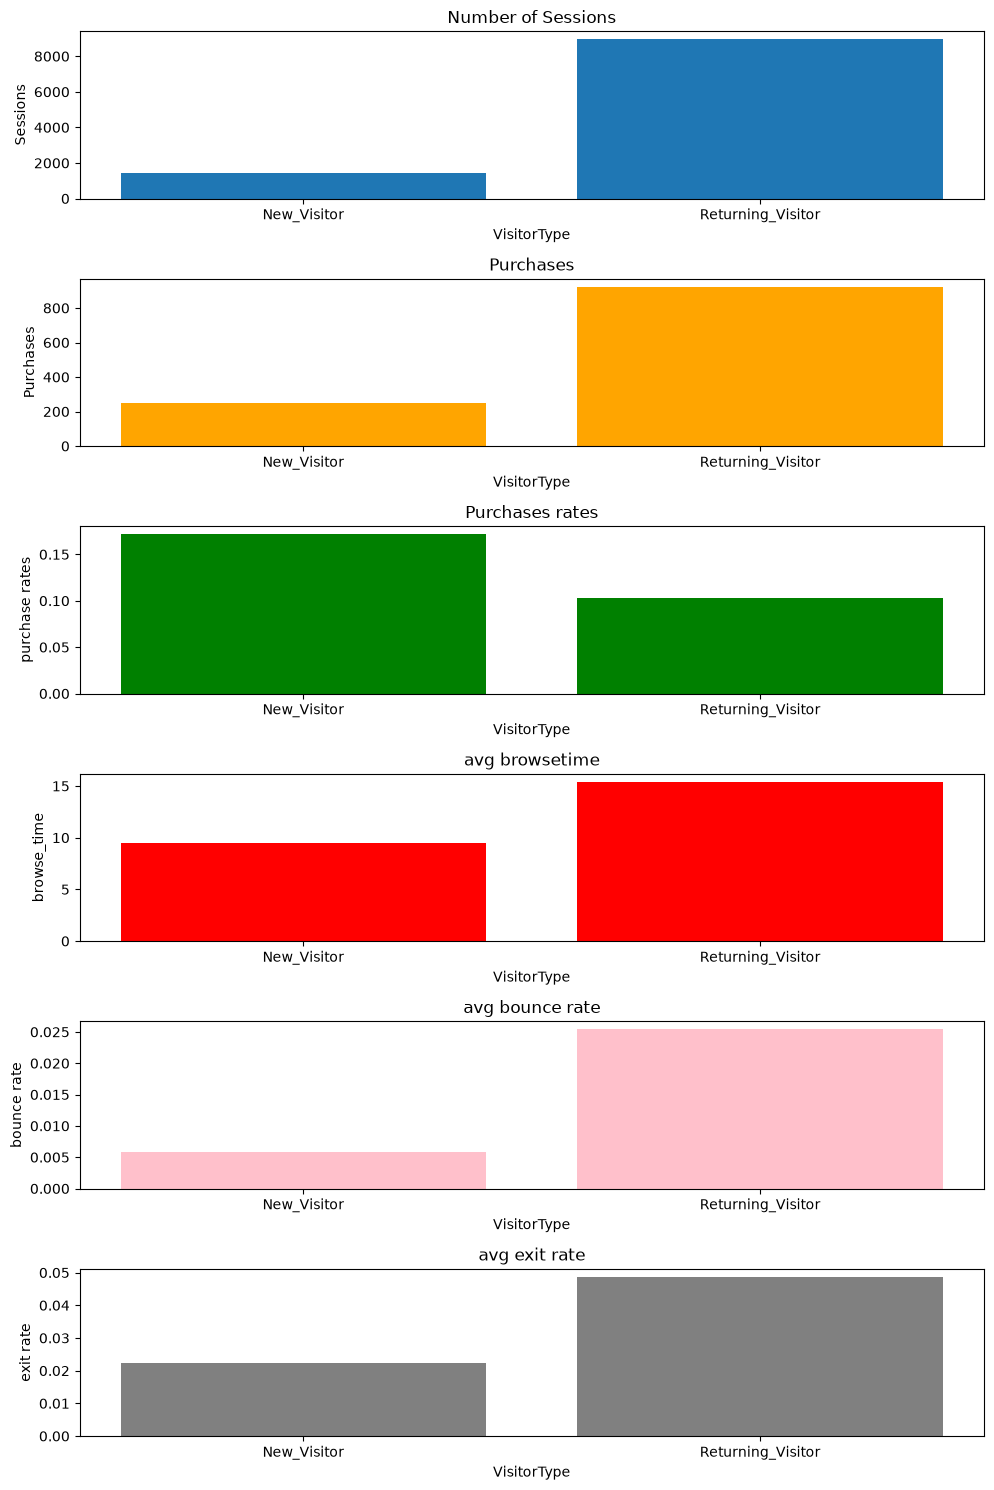

In [24]:
fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(6, 1, figsize=(10, 15), sharex=True)

ax1.bar(new_return['VisitorType'], new_return['sessions'])
ax1.set_ylabel('Sessions')
ax1.set_title('Number of Sessions')

ax2.bar(new_return['VisitorType'], new_return['purchases'], color='orange')
ax2.set_ylabel('Purchases')
ax2.set_title('Purchases')

ax3.bar(new_return['VisitorType'], new_return['purchase_rate'], color='green')
ax3.set_ylabel('purchase rates')
ax3.set_title('Purchases rates')

ax4.bar(new_return['VisitorType'], new_return['browse_time'], color='red')
ax4.set_ylabel('browse_time')
ax4.set_title('avg browsetime')

ax5.bar(new_return['VisitorType'], new_return['avg_bounce_rate'], color='pink')
ax5.set_ylabel('bounce rate')
ax5.set_title('avg bounce rate')

ax6.bar(new_return['VisitorType'], new_return['avg_exit_rates'], color='grey')
ax6.set_ylabel('exit rate')
ax6.set_title('avg exit rate')

for ax in (ax1, ax2, ax3, ax4, ax5, ax6):
    ax.set_xticks(new_return['VisitorType'])                          # a tick at every month
    ax.set_xticklabels(new_return['VisitorType'])                        # name each tick
    ax.tick_params(labelbottom=True)     # show labels even on shared axes
    ax.set_xlabel('VisitorType')

plt.tight_layout()
plt.show()

**Observations**
- Returning visitors make up most sessions and purchases, but new visitors convert at a higher rate (about 17% vs. 10%).
- Returning visitors browse longer (about 15 vs. 9 minutes) but have higher bounce and exit rates.

## 7. Q4–Q5. Relationships with purchase

In [25]:
#Are people who spend more time browsing products more likely to purchase?

corr = final_df[['converted_revenue', 'BounceRates']].corr()
corr

# this is quite weak correlation. close to 0. also the direction is negatvie. higher bounce rate little less likely to end in a purchase.

,converted_revenue,BounceRates
converted_revenue,1.000000,-0.122956
BounceRates,-0.122956,1.000000


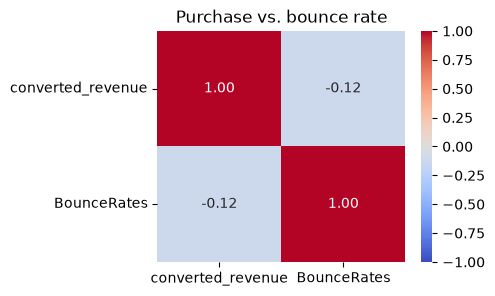

In [26]:
plt.figure(figsize=(4, 3))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Purchase vs. bounce rate')
plt.show()

### Correlation matrix: key variables

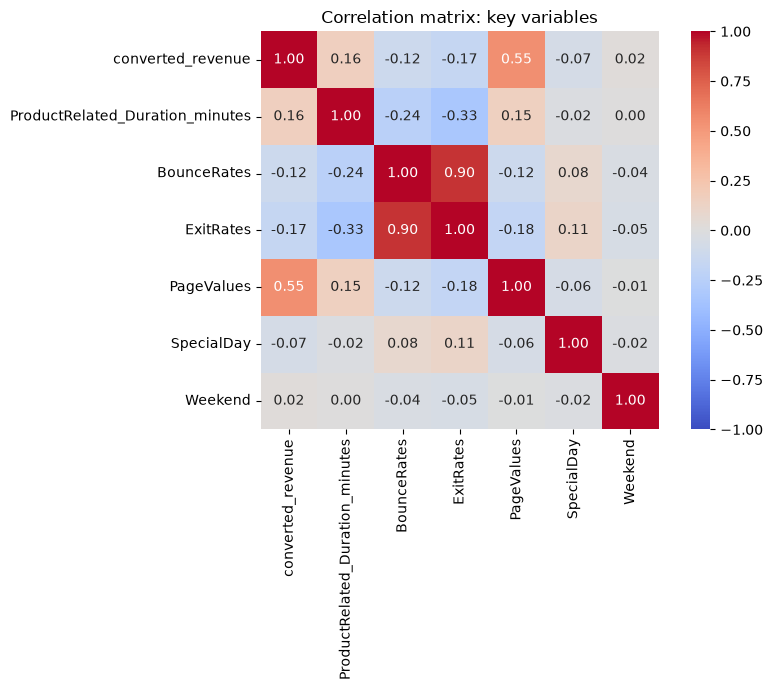

In [27]:
cols = ['converted_revenue', 'ProductRelated_Duration_minutes', 'BounceRates', 'ExitRates',
        'PageValues', 'SpecialDay', 'Weekend']

corr_all = final_df[cols].astype(float).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_all, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation matrix: key variables')
plt.tight_layout()
plt.show()

**How to read it:** the `converted_revenue` row shows each variable's association with purchase.
The other cells show collinearity between predictors: pairs above ~0.8 (e.g., BounceRates and ExitRates) should not both go into a regression.

## 8. Summary and next steps
- **Seasonality:** November has the highest purchase rate; May has high traffic but low conversion.
- **Visitor type:** new visitors convert more often than returning visitors despite shorter browsing.
- **Bounce rate:** weakly and negatively correlated with purchase.
- **Next steps:** test SpecialDay, Weekend, and PageValues further; regression and model comparison are in the modeling notebook.